# 第二章 处理文本数据

In [3]:
# 使用Edith Wharton的短篇小说The Verdict作为训练语料
import urllib.request
import os

url = (
    "https://raw.githubusercontent.com/rasbt/"
    "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
    "the-verdict.txt"
)
file_path = "data/the-verdict.txt"

urllib.request.urlretrieve(url, file_path)

('data/the-verdict.txt', <http.client.HTTPMessage at 0x703f88b852a0>)

In [4]:
# 读取the-verdict.txt
with open(file_path, "r", encoding="utf-8") as f:
    raw_text = f.read()
print(f"Length of text: {len(raw_text)}")
print(raw_text[:99])

Length of text: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


In [5]:
# 使用正则表达式处理The Verdict全文
import re

preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
print(len(preprocessed))
print(preprocessed[:30])

4690
['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


## 将词元转换成词元ID
首先将训练集中的全部文本分词成独立的词元；然后将这些词元按字母顺序进行排列，并删除重复的词元；接下来将唯一的词元聚合到一张词汇表中，该词汇表定义了每个唯一的词元到唯一的整数值的映射。
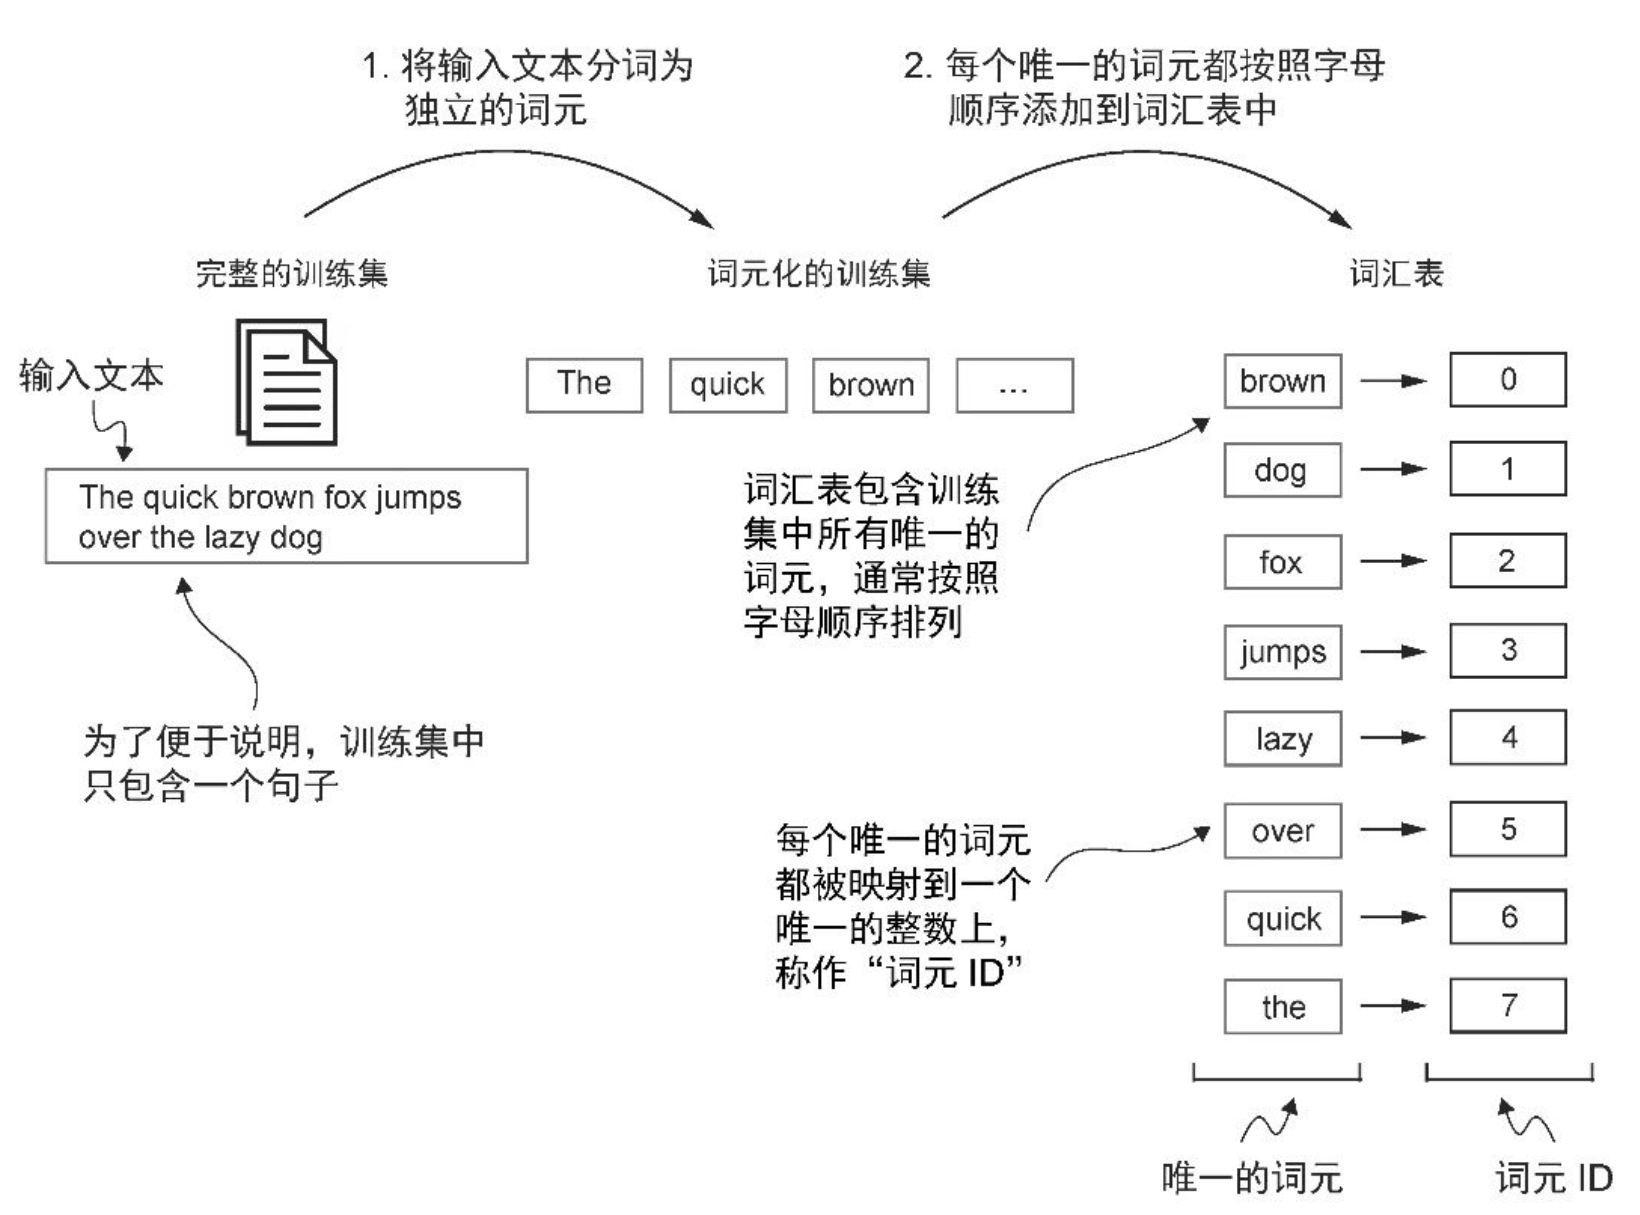

In [6]:
# 构建包含所有唯一词元的列表
all_words = sorted(set(preprocessed))
vocab_size = len(all_words)
print(vocab_size)

# 创建词汇表
vocab = {token:integer for integer, token in enumerate(all_words)}
for i, item in enumerate(vocab.items()):
    print(item)
    if i>=10:
        break

1130
('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)


In [7]:
# 实现一个简单的文本分词器
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}

    # 处理输入文本，将其转换为词元ID
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    # 将词元ID转换回文本
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # 移除特定标点符号前的空格
        text = re.sub(r'\s+([,.:;?_!"()\'])', r'\1', text)
        return text

In [8]:
# 测试分词器的效果
tokenizer = SimpleTokenizerV1(vocab)
text = """"It's the last he painted, you know,"
       Mrs. Gisburn said with pardonable pride."""
# 将文本转换成词元ID
ids = tokenizer.encode(text)
print(ids)
# 将词元ID转换回文本
print(tokenizer.decode(ids))

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]
" It' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.


In [9]:
# 测试处理训练集外的新样本
text = "Hello, do you like tea?"
print(tokenizer.encode(text))

KeyError: 'Hello'

In [11]:
# 将特殊词元<|unk|>和<|endoftext|>添加到词汇表中，<|unk|>用于处理词汇表中不存在的单词，<|endoftext|>用于区分不相关的文本
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {token:integer for integer,token in enumerate(all_tokens)}

print(len(vocab.items()))
for i, item in enumerate(list(vocab.items())[-5:]):
    print(item)

1132
('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


In [12]:
# 实现能够处理未知单词的文本分词器
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}

    # 处理输入文本，将其转换为词元ID
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        # 用<|unk|>词元替代未知单词
        preprocessed = [item if item in self.str_to_int else "<|unk|>" for item in preprocessed]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    # 将词元ID转换回文本
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # 移除特定标点符号前的空格
        text = re.sub(r'\s+([,.:;?_!"()\'])', r'\1', text)
        return text

In [13]:
# 测试新的文本分词器
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
text = " <|endoftext|> ".join((text1, text2))
print(text)
tokenizer = SimpleTokenizerV2(vocab)
ids = tokenizer.encode(text)
print(ids)
print(tokenizer.decode(ids))

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.
[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]
<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.


In [14]:
# 后续使用gpt2预训练好的分词器，该分词器为使用BPE算法训练而来
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

In [15]:
# 将文本转换为词元ID
text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
     "of someunknownPlace."
)
integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)
# 将词元ID转换回文本
strings = tokenizer.decode(integers)
print(strings)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]
Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


In [16]:
# 使用gpt-2分词器对文本The Verdict进行全文分词
enc_text = tokenizer.encode(raw_text)
print(len(enc_text))

5145


## 使用滑动窗口进行数据采样
给定一个文本样本，我们从中提取子样本，作为输入块提供给大语言模型。在训练过程中，模型的任务是预测输入块之后的下一个词，我们会屏蔽目标词之后的所有单词
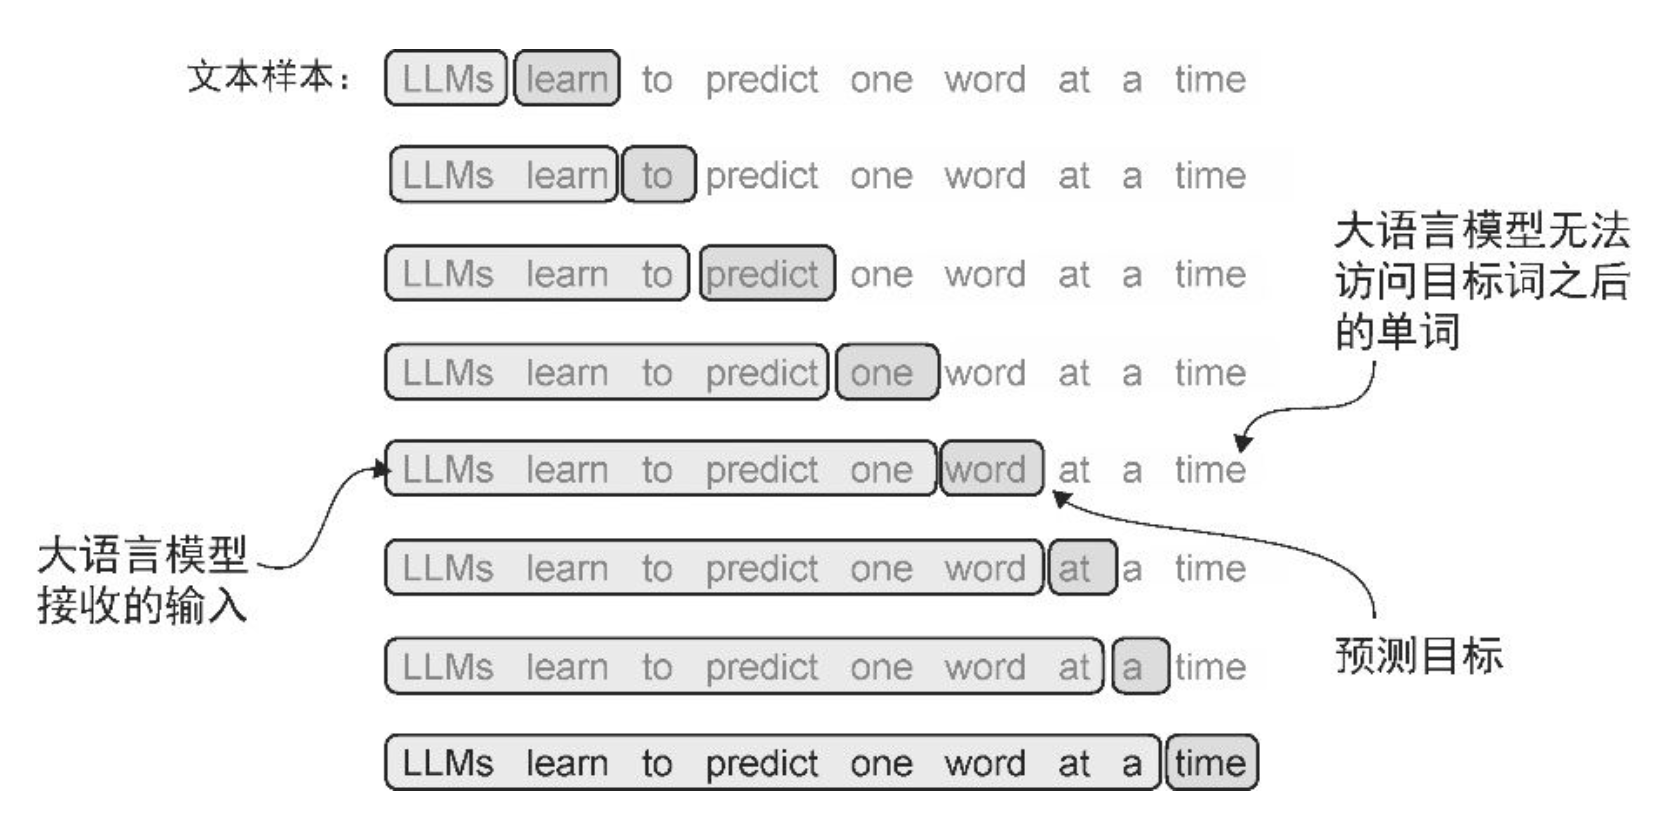

In [17]:
# 构建用于批处理输入和目标的数据集
import torch
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        # 对全部文本进行分词
        token_ids = tokenizer.encode(txt)
        # 使用滑动窗口将文本划分为长度为max_length的重叠序列
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i: i+max_length]
            target_chunk = token_ids[i+1: i+max_length+1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [20]:
# 创建用于批量生成输入-目标对的数据加载器函数
def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):
    # 初始化分词器
    tokenizer = tiktoken.get_encoding("gpt2")
    # 创建数据集
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    # 如果drop_last为True且批次大小小于指定的batch_size，则会删除最后一批，以防止在训练期间出现损失剧增
    data_loader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last, num_workers=num_workers)
    return data_loader

In [21]:
# 创建数据加载器
dataloader = create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False
)
data_iter = iter(dataloader)
# 打印第一个batch
first_batch = next(data_iter)
print(first_batch)
# 打印第二个batch
second_batch = next(data_iter)
print(second_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]
[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


In [26]:
# 设置批次大于1，同时stride=max_length，不会跳过任何一个单词，同时避免不同批次之间的数据重叠
max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length, stride=max_length,
    shuffle=False
)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\nTargets:\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


## 创建词元嵌入
为大语言模型训练准备输入文本的最后一步是将词元ID转换为嵌入向量，如图所示。在初始阶段，必须用随机值初始化这些嵌入权重，这是大语言模型学习的起点。
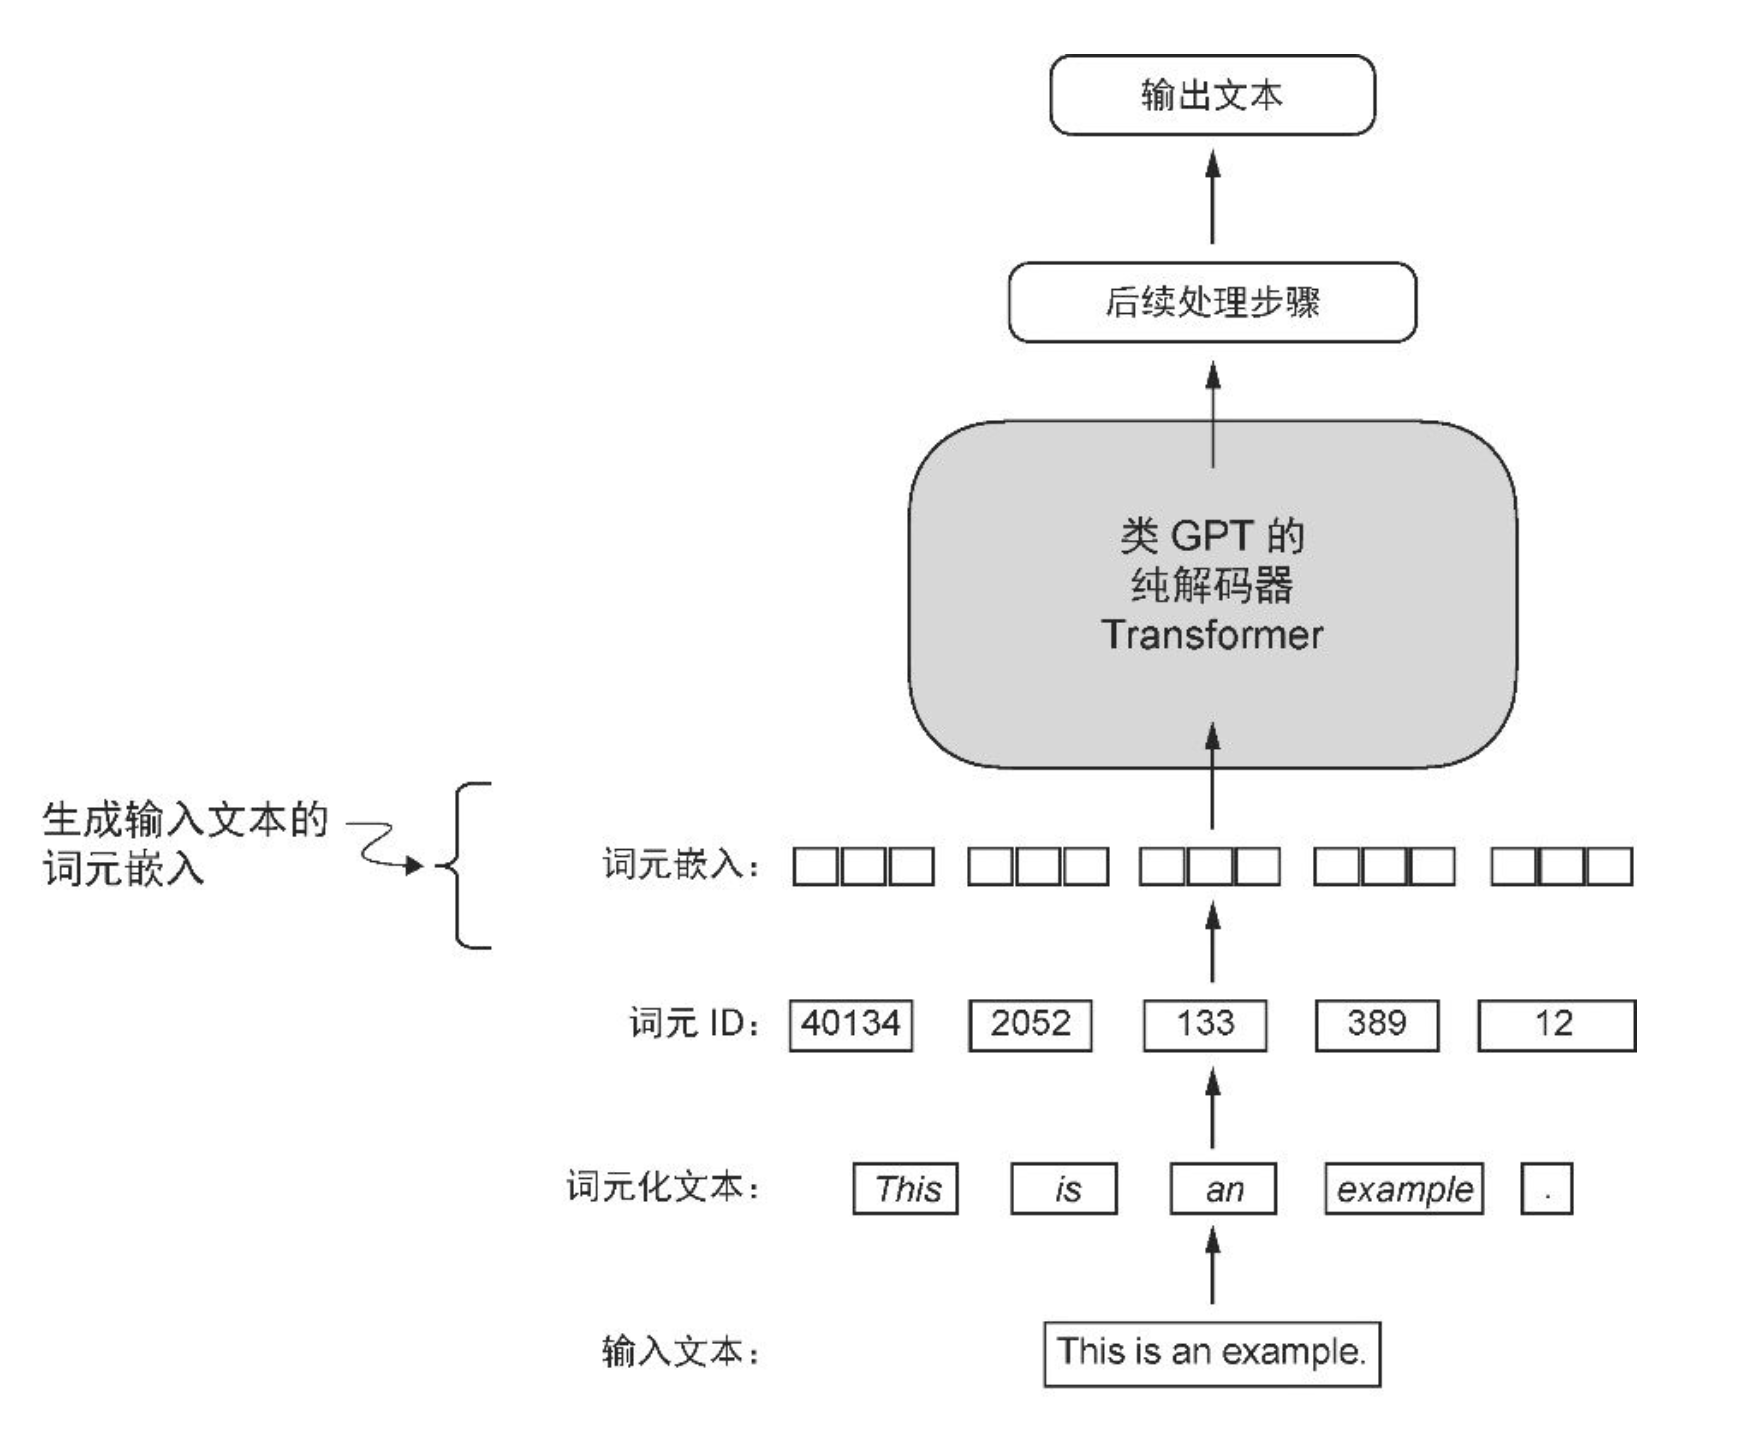

In [27]:
# 创建词嵌入层
vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [28]:
# 使用嵌入层将输入的词元ID嵌入256维向量中
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

torch.Size([8, 4, 256])


In [29]:
# 为了采取GPT模型所采用的绝对位置嵌入，只需创建一个维度与token_embedding_layer相同的嵌入层
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
print(pos_embeddings.shape)

torch.Size([4, 256])


In [30]:
# 输入向量等于词嵌入向量+位置嵌入向量
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

torch.Size([8, 4, 256])
